In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Layer 0: min rank = 62
The bottom 16 values hold 0.0000% of the energy


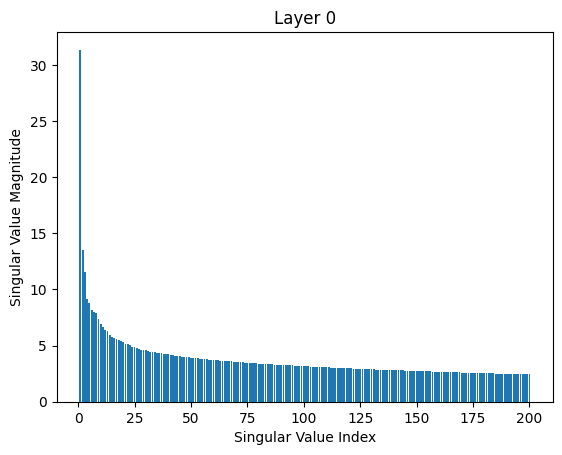

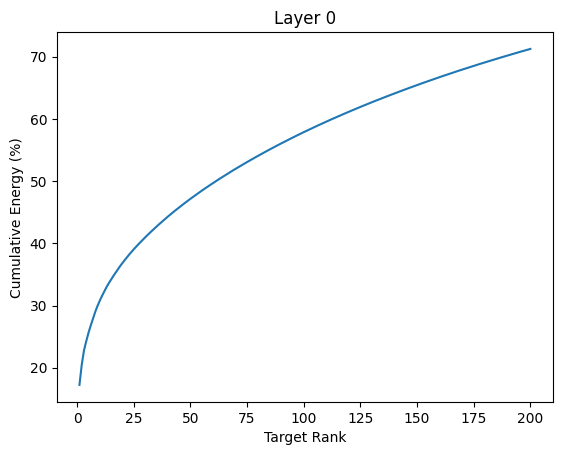

Layer 7: min rank = 120
The bottom 16 values hold 0.0000% of the energy


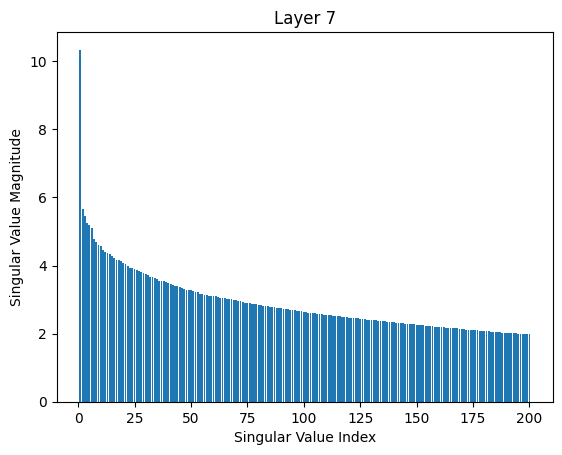

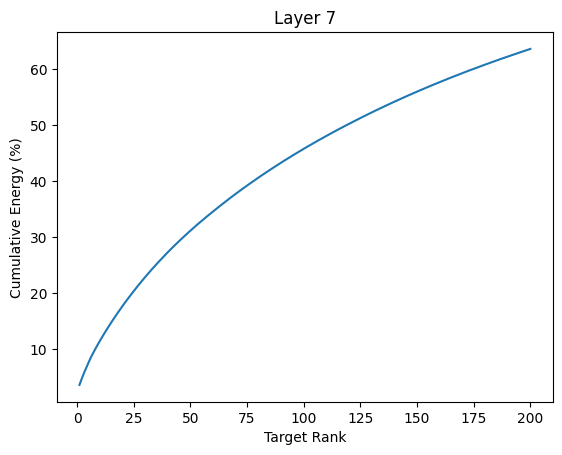

Layer 15: min rank = 84
The bottom 16 values hold 0.0000% of the energy


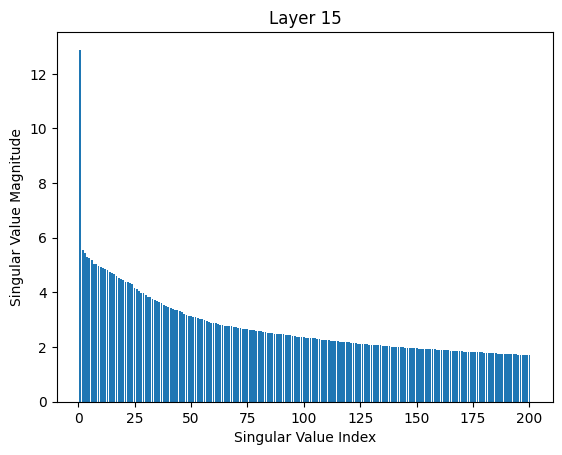

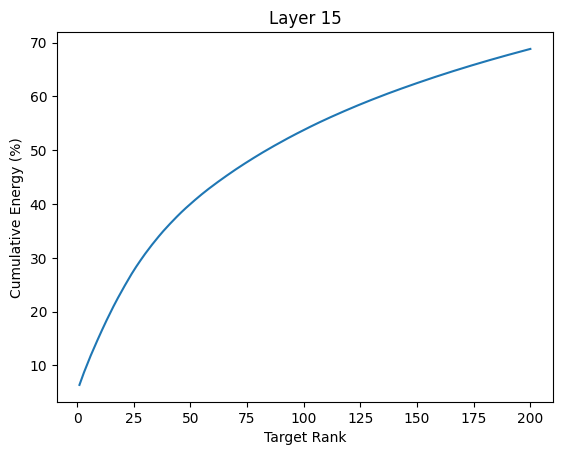

In [5]:
# TODO for Question 4
"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""
for k in [0, 7, 15]:
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    min_rank = (energy_ratios >= 50).nonzero()[0].item() + 1
    print(f'Layer {k}: min rank = {min_rank}')
    print(f'The bottom 16 values hold {100 - energy_ratios[-17]:.4f}% of the energy')

    plt.bar(range(1, 201), S[:200])
    plt.xlabel('Singular Value Index')
    plt.ylabel('Singular Value Magnitude')
    plt.title(f'Layer {k}')
    plt.savefig(f'layer{k}_singular_values.png')
    plt.show()

    plt.plot(range(1, 201), energy_ratios[:200])
    plt.xlabel('Target Rank')
    plt.ylabel('Cumulative Energy (%)')
    plt.title(f'Layer {k}')
    plt.savefig(f'layer{k}_cumulative_energy.png')
    plt.show()